# Model Training and Evaluation

## Objective

This notebook develops and compares supervised machine learning models for predicting collision injury severity.

The prediction task is binary classification:

- `0` = Non-Fatal Injury
- `1` = Fatal Injury

The modeling workflow includes:

- feature selection;
- categorical encoding;
- numeric scaling;
- stratified training, validation, and test splitting;
- Decision Tree baseline training;
- Random Forest training and tuning;
- evaluation using Accuracy, Precision, Recall, and F1-score;
- confusion matrix and ROC analysis;
- selection and saving of the best model and preprocessing pipeline.

### Load the Processed Dataset and Modelling Libraries

This step imports the libraries required for preprocessing, model training, evaluation, and visualization. It also locates the project root and loads the cleaned collision-level dataset from the `data/processed/` folder so the modelling workflow uses the same prepared data created in the preprocessing notebook.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Load processed collision-level dataset
data_path = (
    project_root
    / "data"
    / "processed"
    / "processed_collisions.csv"
)

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7610, 30)


,collision_id,accdate,stname1,stname2,per_inv,acclass,accloc,traffictl,impactype,visible,...,distracted,cyclist,motorcyclist,other_micromobility,older_adult,pedestrian,red_light,school_child,heavy_truck,target
0,2006:893184,2006-01-01T02:36:00,WOODBINE AVE,O CONNOR DR,8,Non-Fatal Injury,Intersection-Related,No Control,Approaching Head On,Clear,...,False,False,False,False,False,False,False,True,False,0
1,2006:909646,2006-01-01T03:15:00,DANFORTH AVE,WEST LYNN AVE,5,Non-Fatal Injury,Intersection-Related,No Control,SMV Other,Snow,...,True,False,False,False,False,False,False,True,False,0
2,2026:6000734335,2026-04-10T06:10:00,ALBION RD,FINCH AV W,3,Non-Fatal Injury,Intersection-Related,Traffic Signal,SMV Other,Rain,...,False,False,False,False,False,True,False,False,False,0
3,2026:6001470477,2026-07-15T18:33:00,28 CARNFORTH RD,LAWRENCE AV E,2,Non-Fatal Injury,Non-Intersection,Unknown,Approaching Head On,Clear,...,False,False,True,False,False,False,False,True,False,0
4,2026:6001482161,2026-07-17T09:39:00,HIGHWAY 2A E,MEADOWVALE RD,5,Non-Fatal Injury,Non-Intersection,No Control,Rear End,Clear,...,False,False,False,False,False,False,False,True,False,0


### Engineer Time Features and Define Predictors

This step converts the collision timestamp into separate `year`, `month`, `day_of_week`, and `hour` features. It also removes identifiers, raw date fields, high-cardinality street names, the original injury-class label, and the target from the predictor matrix so that only appropriate modelling features remain.

In [2]:
# Convert collision date to datetime
df["accdate"] = pd.to_datetime(df["accdate"])

# Create useful date/time features
df["year"] = df["accdate"].dt.year
df["month"] = df["accdate"].dt.month
df["day_of_week"] = df["accdate"].dt.dayofweek
df["hour"] = df["accdate"].dt.hour

# Columns not used as predictors
columns_to_exclude = [
    "collision_id",
    "accdate",
    "stname1",
    "stname2",
    "acclass",
    "target"
]

# Predictor matrix
X = df.drop(columns=columns_to_exclude)

# Target
y = df["target"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nPredictor columns:")
print(X.columns.tolist())

Predictor shape: (7610, 28)
Target shape: (7610,)

Predictor columns:
['per_inv', 'accloc', 'traffictl', 'impactype', 'visible', 'light', 'rdsfcond', 'road_class', 'failtorem', 'longitude', 'latitude', 'wardname', 'division', 'neighbourhood', 'aggressive', 'distracted', 'cyclist', 'motorcyclist', 'other_micromobility', 'older_adult', 'pedestrian', 'red_light', 'school_child', 'heavy_truck', 'year', 'month', 'day_of_week', 'hour']


### Identify Predictor Types

This step separates the modelling features into numeric, categorical, and Boolean groups. Identifying feature types is necessary because each group requires different preprocessing: numeric features are scaled, categorical features are one-hot encoded, and Boolean features are passed through unchanged.

In [4]:
# Identify predictor types

numeric_features = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

boolean_features = X.select_dtypes(
    include=["bool"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nBoolean features:")
print(boolean_features)

print("\nFeature counts:")
print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))
print("Boolean:", len(boolean_features))
print("Total:", (
    len(numeric_features)
    + len(categorical_features)
    + len(boolean_features)
))

Numeric features:
['per_inv', 'longitude', 'latitude', 'year', 'month', 'day_of_week', 'hour']

Categorical features:
['accloc', 'traffictl', 'impactype', 'visible', 'light', 'rdsfcond', 'road_class', 'wardname', 'division', 'neighbourhood']

Boolean features:
['failtorem', 'aggressive', 'distracted', 'cyclist', 'motorcyclist', 'other_micromobility', 'older_adult', 'pedestrian', 'red_light', 'school_child', 'heavy_truck']

Feature counts:
Numeric: 7
Categorical: 10
Boolean: 11
Total: 28


### Split the Dataset for Model Development

This step divides the predictors and target into training, validation, and test sets using a 70/15/15 split. Stratified sampling preserves the Fatal and Non-Fatal class proportions in each subset, while a fixed random state makes the split reproducible. The validation set is used for model selection and tuning, while the test set is reserved for final evaluation.

In [5]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: temporary set into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (5327, 28) (5327,)
Validation set: (1141, 28) (1141,)
Test set: (1142, 28) (1142,)

Training target distribution:
target
0    0.86
1    0.14
Name: proportion, dtype: float64

Validation target distribution:
target
0    0.86
1    0.14
Name: proportion, dtype: float64

Test target distribution:
target
0    0.86
1    0.14
Name: proportion, dtype: float64


### Import Preprocessing Tools

This step imports `ColumnTransformer`, `OneHotEncoder`, and `StandardScaler`, which are used to build a consistent preprocessing pipeline. These tools allow different transformations to be applied to numeric and categorical features within a single reusable workflow.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

### Build the Preprocessing Pipeline

This step creates a `ColumnTransformer` that applies the correct preprocessing to each feature type. Numeric features are standardized with `StandardScaler`, categorical features are converted to one-hot encoded variables with `OneHotEncoder`, and Boolean features are passed through unchanged. Combining these transformations into one pipeline ensures that the same preprocessing can be reused consistently during model training and prediction.

In [7]:
# Build preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "boolean",
            "passthrough",
            boolean_features
        )
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (5327, 294)
Processed validation shape: (1141, 294)
Processed test shape: (1142, 294)


### Import Classification Model and Evaluation Metrics

This step imports the Decision Tree classifier and the evaluation metrics used throughout the modelling process. Accuracy, precision, recall, F1-score, the confusion matrix, and the classification report are used to assess model performance from multiple perspectives, which is especially important because the target classes are imbalanced.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### Train and Evaluate the Decision Tree Baseline

This step trains a Decision Tree classifier on the preprocessed training data using a maximum depth of 5 and balanced class weights. The model is then evaluated on the validation set using accuracy, precision, recall, F1-score, a classification report, and a confusion matrix. These results establish a baseline for comparison with the Random Forest model.

In [9]:
# Train baseline Decision Tree classifier

decision_tree = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

decision_tree.fit(X_train_processed, y_train)

# Predict on validation set only
y_val_pred_tree = decision_tree.predict(X_val_processed)

# Validation metrics
tree_accuracy = accuracy_score(y_val, y_val_pred_tree)
tree_precision = precision_score(y_val, y_val_pred_tree)
tree_recall = recall_score(y_val, y_val_pred_tree)
tree_f1 = f1_score(y_val, y_val_pred_tree)

print("Decision Tree - Validation Results")
print("----------------------------------")
print(f"Accuracy : {tree_accuracy:.3f}")
print(f"Precision: {tree_precision:.3f}")
print(f"Recall   : {tree_recall:.3f}")
print(f"F1-score : {tree_f1:.3f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_tree))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tree))

Decision Tree - Validation Results
----------------------------------
Accuracy : 0.654
Precision: 0.206
Recall   : 0.512
F1-score : 0.293

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.68      0.77       981
           1       0.21      0.51      0.29       160

    accuracy                           0.65      1141
   macro avg       0.55      0.59      0.53      1141
weighted avg       0.80      0.65      0.70      1141

Confusion Matrix:
[[664 317]
 [ 78  82]]


### Import the Random Forest Classifier

This step imports the `RandomForestClassifier`, which is used as the second supervised learning model. Random Forest combines many decision trees and is well suited to tabular data with a mixture of numeric, categorical, and Boolean features.

In [10]:
from sklearn.ensemble import RandomForestClassifier

### Train and Evaluate the Initial Random Forest Model

This step trains a Random Forest classifier using 200 trees, a maximum depth of 10, and balanced class weights. The model is evaluated on the validation set using accuracy, precision, recall, F1-score, a classification report, and a confusion matrix. These results are compared with the Decision Tree baseline to determine whether the ensemble model provides better overall performance.

In [11]:
# Train Random Forest classifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

# Predict on validation set only
y_val_pred_rf = random_forest.predict(X_val_processed)

# Validation metrics
rf_accuracy = accuracy_score(y_val, y_val_pred_rf)
rf_precision = precision_score(y_val, y_val_pred_rf)
rf_recall = recall_score(y_val, y_val_pred_rf)
rf_f1 = f1_score(y_val, y_val_pred_rf)

print("Random Forest - Validation Results")
print("----------------------------------")
print(f"Accuracy : {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall   : {rf_recall:.3f}")
print(f"F1-score : {rf_f1:.3f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

Random Forest - Validation Results
----------------------------------
Accuracy : 0.784
Precision: 0.295
Recall   : 0.388
F1-score : 0.335

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87       981
           1       0.30      0.39      0.34       160

    accuracy                           0.78      1141
   macro avg       0.59      0.62      0.60      1141
weighted avg       0.81      0.78      0.80      1141

Confusion Matrix:
[[833 148]
 [ 98  62]]


### Tune the Random Forest Hyperparameters

This step tests several combinations of Random Forest hyperparameters, including the number of trees, maximum tree depth, and minimum number of samples required to split an internal node. Each configuration is evaluated on the validation set using F1-score, and the best-performing combination is selected for the final Random Forest model.

In [12]:
from itertools import product

rf_results = []

n_estimators_options = [100, 200]
max_depth_options = [5, 10, None]
min_samples_split_options = [2, 5]

for n_estimators, max_depth, min_samples_split in product(
    n_estimators_options,
    max_depth_options,
    min_samples_split_options
):
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)

    y_val_pred = model.predict(X_val_processed)

    rf_results.append({
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "min_samples_split": min_samples_split,
        "accuracy": accuracy_score(y_val, y_val_pred),
        "precision": precision_score(y_val, y_val_pred),
        "recall": recall_score(y_val, y_val_pred),
        "f1": f1_score(y_val, y_val_pred)
    })

rf_results_df = pd.DataFrame(rf_results)

rf_results_df.sort_values(
    by="f1",
    ascending=False
).head(10)

,n_estimators,max_depth,min_samples_split,accuracy,precision,recall,f1
9,200,10.0,5,0.782647,0.294393,0.39375,0.336898
3,100,10.0,5,0.774759,0.286344,0.40625,0.335917
8,200,10.0,2,0.784400,0.295238,0.38750,0.335135
2,100,10.0,2,0.783523,0.291866,0.38125,0.330623
6,200,5.0,2,0.668712,0.228856,0.57500,0.327402
1,100,5.0,5,0.666082,0.223058,0.55625,0.318426
0,100,5.0,2,0.661700,0.221675,0.56250,0.318021
7,200,5.0,5,0.658195,0.219512,0.56250,0.315789
5,100,NaN,5,0.863278,0.700000,0.04375,0.082353
11,200,NaN,5,0.861525,0.625000,0.03125,0.059524


### Train the Selected Tuned Random Forest

This step trains the final Random Forest configuration selected during hyperparameter tuning. The model uses 200 trees, a maximum depth of 10, a minimum of 5 samples required to split an internal node, and balanced class weights. Its performance is then evaluated on the validation set to confirm that the tuned configuration improves the overall balance of classification metrics.

In [13]:
# Train the selected tuned Random Forest

best_random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

best_random_forest.fit(X_train_processed, y_train)

# Validation predictions
y_val_pred_best_rf = best_random_forest.predict(X_val_processed)

print("Tuned Random Forest - Validation Results")
print("----------------------------------------")
print(f"Accuracy : {accuracy_score(y_val, y_val_pred_best_rf):.3f}")
print(f"Precision: {precision_score(y_val, y_val_pred_best_rf):.3f}")
print(f"Recall   : {recall_score(y_val, y_val_pred_best_rf):.3f}")
print(f"F1-score : {f1_score(y_val, y_val_pred_best_rf):.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_best_rf))

Tuned Random Forest - Validation Results
----------------------------------------
Accuracy : 0.783
Precision: 0.294
Recall   : 0.394
F1-score : 0.337

Confusion Matrix:
[[830 151]
 [ 97  63]]


### Import ROC Evaluation Tools

This step imports the functions required to calculate the Receiver Operating Characteristic (ROC) curve and ROC AUC score, along with Matplotlib for visualization. These tools provide an additional way to evaluate how well the classifier distinguishes Fatal Injury collisions from Non-Fatal Injury collisions across different decision thresholds.

In [14]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

### Evaluate the Tuned Random Forest with ROC AUC

This step uses the tuned Random Forest to generate predicted probabilities for the Fatal Injury class on the validation set. These probabilities are used to calculate the ROC AUC score and plot the ROC curve, which shows how well the model distinguishes Fatal from Non-Fatal collisions across different classification thresholds.

Validation ROC AUC: 0.682


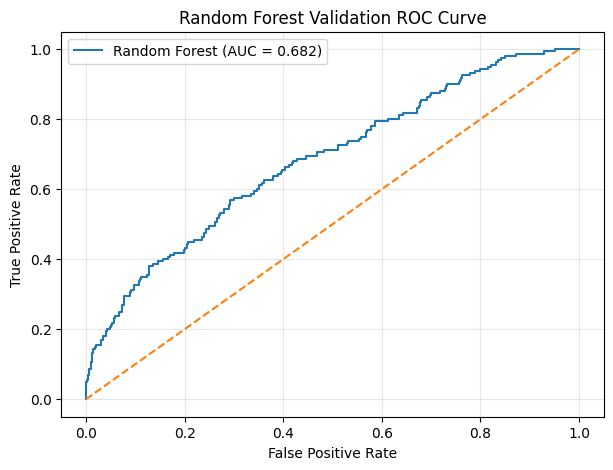

In [15]:
# Predicted probabilities for the Fatal class
y_val_prob_rf = best_random_forest.predict_proba(X_val_processed)[:, 1]

# ROC AUC
rf_roc_auc = roc_auc_score(y_val, y_val_prob_rf)

# ROC curve values
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob_rf)

print(f"Validation ROC AUC: {rf_roc_auc:.3f}")

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {rf_roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Compare Classification Thresholds

This step evaluates several probability thresholds between 0.30 and 0.50 using the validation set. For each threshold, accuracy, precision, recall, and F1-score are calculated to show how changing the decision threshold affects the trade-off between identifying more Fatal Injury collisions and increasing false positives.

In [16]:
# Compare different probability thresholds on the validation set

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    y_val_pred_threshold = (
        y_val_prob_rf >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_val,
            y_val_pred_threshold
        ),
        "precision": precision_score(
            y_val,
            y_val_pred_threshold
        ),
        "recall": recall_score(
            y_val,
            y_val_pred_threshold
        ),
        "f1": f1_score(
            y_val,
            y_val_pred_threshold
        )
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

threshold_results_df

,threshold,accuracy,precision,recall,f1
0,0.30,0.281332,0.158385,0.95625,0.271758
1,0.35,0.370727,0.167064,0.87500,0.280561
2,0.40,0.503067,0.183515,0.73750,0.293898
3,0.45,0.649430,0.219626,0.58750,0.319728
4,0.50,0.782647,0.294393,0.39375,0.336898


### Evaluate the Final Random Forest on the Test Set

This step performs the final evaluation of the tuned Random Forest using the held-out test set. The model is assessed with accuracy, precision, recall, F1-score, ROC AUC, a classification report, and a confusion matrix. Because the test set was not used during tuning, these results provide the final estimate of model performance on unseen data.

In [17]:
# Final evaluation on the untouched test set

y_test_pred_rf = best_random_forest.predict(
    X_test_processed
)

y_test_prob_rf = best_random_forest.predict_proba(
    X_test_processed
)[:, 1]

test_accuracy = accuracy_score(
    y_test,
    y_test_pred_rf
)

test_precision = precision_score(
    y_test,
    y_test_pred_rf
)

test_recall = recall_score(
    y_test,
    y_test_pred_rf
)

test_f1 = f1_score(
    y_test,
    y_test_pred_rf
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_prob_rf
)

print("Tuned Random Forest - Final Test Results")
print("----------------------------------------")
print(f"Accuracy : {test_accuracy:.3f}")
print(f"Precision: {test_precision:.3f}")
print(f"Recall   : {test_recall:.3f}")
print(f"F1-score : {test_f1:.3f}")
print(f"ROC AUC  : {test_roc_auc:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_rf
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_rf
    )
)

Tuned Random Forest - Final Test Results
----------------------------------------
Accuracy : 0.772
Precision: 0.273
Recall   : 0.375
F1-score : 0.316
ROC AUC  : 0.687

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.84      0.86       982
           1       0.27      0.38      0.32       160

    accuracy                           0.77      1142
   macro avg       0.58      0.61      0.59      1142
weighted avg       0.80      0.77      0.79      1142

Confusion Matrix:
[[822 160]
 [100  60]]


### Evaluate the Decision Tree on the Final Test Set

This step evaluates the baseline Decision Tree on the same held-out test set used for the tuned Random Forest. Using the same test data allows a fair final comparison between the two models based on accuracy, precision, recall, F1-score, and the confusion matrix.

In [25]:
# Final Decision Tree evaluation on the same test set

y_test_pred_tree = decision_tree.predict(
    X_test_processed
)

tree_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_tree
)

tree_test_precision = precision_score(
    y_test,
    y_test_pred_tree
)

tree_test_recall = recall_score(
    y_test,
    y_test_pred_tree
)

tree_test_f1 = f1_score(
    y_test,
    y_test_pred_tree
)

print("Decision Tree - Final Test Results")
print("----------------------------------")
print(f"Accuracy : {tree_test_accuracy:.3f}")
print(f"Precision: {tree_test_precision:.3f}")
print(f"Recall   : {tree_test_recall:.3f}")
print(f"F1-score : {tree_test_f1:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_tree
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred_tree
    )
)

Decision Tree - Final Test Results
----------------------------------
Accuracy : 0.625
Precision: 0.187
Recall   : 0.500
F1-score : 0.272

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.65      0.75       982
           1       0.19      0.50      0.27       160

    accuracy                           0.63      1142
   macro avg       0.54      0.57      0.51      1142
weighted avg       0.79      0.63      0.68      1142

Confusion Matrix:
[[634 348]
 [ 80  80]]


### Import Confusion Matrix Visualization Tool

This step imports `ConfusionMatrixDisplay`, which is used to visualize the final classification results. The confusion matrix makes it easier to see the number of correct predictions, false positives, and false negatives for the selected model.

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

### Visualize the Final Confusion Matrix

This step displays the confusion matrix for the tuned Random Forest on the test set. The visualization shows how many Non-Fatal and Fatal Injury collisions were classified correctly and highlights the false positives and false negatives produced by the final model.

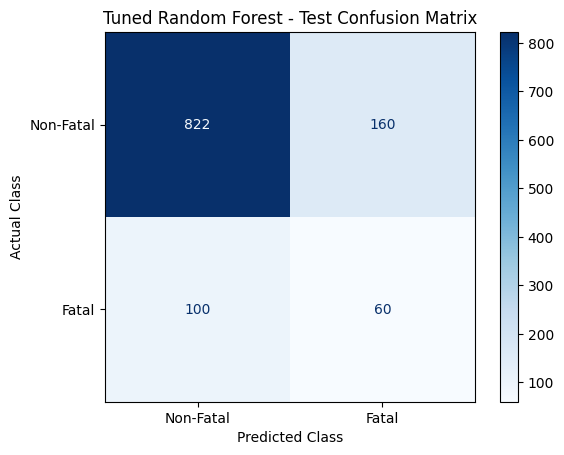

In [19]:
# Final confusion matrix plot

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_rf,
    display_labels=["Non-Fatal", "Fatal"],
    cmap="Blues"
)

plt.title("Tuned Random Forest - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

### Plot the Final Test ROC Curve

This step generates the ROC curve for the tuned Random Forest using predicted probabilities from the final test set. The curve shows the trade-off between the true positive rate and false positive rate across classification thresholds, while the ROC AUC summarizes the model's overall ability to distinguish Fatal from Non-Fatal Injury collisions.

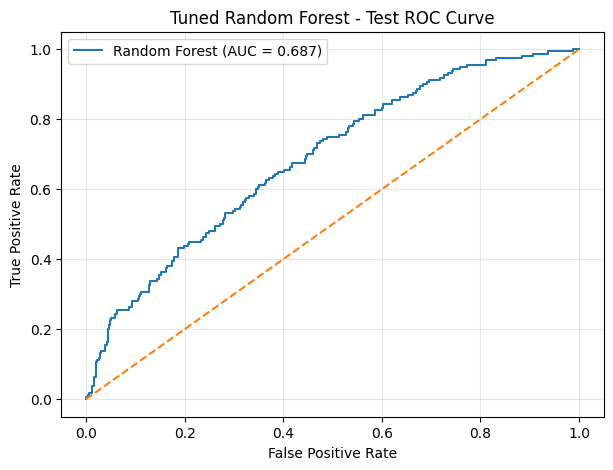

In [20]:
# Final ROC curve

test_fpr, test_tpr, _ = roc_curve(
    y_test,
    y_test_prob_rf
)

plt.figure(figsize=(7, 5))

plt.plot(
    test_fpr,
    test_tpr,
    label=f"Random Forest (AUC = {test_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Tuned Random Forest - Test ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Save ROC Curve Data for the Dashboard

This step stores the final test-set ROC curve coordinates in a CSV file inside the `models` folder. Saving the false positive rate and true positive rate allows the Streamlit dashboard to reproduce the final ROC curve without recalculating model predictions each time the application runs.

In [24]:
# Save final test ROC curve data for the dashboard

roc_curve_df = pd.DataFrame(
    {
        "false_positive_rate": test_fpr,
        "true_positive_rate": test_tpr
    }
)

roc_path = (
    project_root
    / "models"
    / "test_roc_curve.csv"
)

roc_curve_df.to_csv(
    roc_path,
    index=False
)

print("ROC curve data saved to:")
print(roc_path)

print("\nROC points:", len(roc_curve_df))

ROC curve data saved to:
c:\Git\AI Software Development\CST8504_Applying_AI_Technics\assignment1_prediction_dashboard\models\test_roc_curve.csv

ROC points: 249


### Import Model Serialization Tool

This step imports `joblib`, which is used to save the fitted preprocessing pipeline and the final trained Random Forest model to disk. Saving these objects allows the dashboard to load and reuse the exact same preprocessing and model without retraining.

In [21]:
import joblib

### Save the Final Preprocessor and Model

This step creates the `models` directory if needed and saves both the fitted preprocessing pipeline and the tuned Random Forest model using `joblib`. Storing both objects ensures that future predictions use the exact same feature transformations that were applied during model training.

In [22]:
# Save the fitted preprocessor and final model

models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)

preprocessor_path = models_dir / "preprocessor.pkl"
model_path = models_dir / "best_random_forest.pkl"

joblib.dump(preprocessor, preprocessor_path)
joblib.dump(best_random_forest, model_path)

print("Saved preprocessor to:")
print(preprocessor_path)

print("\nSaved model to:")
print(model_path)

Saved preprocessor to:
c:\Git\AI Software Development\CST8504_Applying_AI_Technics\assignment1_prediction_dashboard\models\preprocessor.pkl

Saved model to:
c:\Git\AI Software Development\CST8504_Applying_AI_Technics\assignment1_prediction_dashboard\models\best_random_forest.pkl


### Verify the Saved Model and Preprocessor

This step reloads the saved preprocessing pipeline and Random Forest model from the `models` folder and uses them to make sample predictions. The verification confirms that both files were saved correctly and that the complete prediction workflow can be restored and used without retraining.

In [23]:
# Verify saved model and preprocessor

loaded_preprocessor = joblib.load(
    models_dir / "preprocessor.pkl"
)

loaded_model = joblib.load(
    models_dir / "best_random_forest.pkl"
)

# Transform a few original test rows
sample_X = X_test.iloc[:5]

sample_processed = loaded_preprocessor.transform(
    sample_X
)

# Make predictions
sample_predictions = loaded_model.predict(
    sample_processed
)

sample_probabilities = loaded_model.predict_proba(
    sample_processed
)[:, 1]

print("Predictions:")
print(sample_predictions)

print("\nFatal probabilities:")
print(sample_probabilities)

Predictions:
[0 0 0 0 0]

Fatal probabilities:
[0.42748184 0.31806051 0.25092032 0.37949023 0.43276753]
